# Proyecto de Datos

Se procederá a realizar un análisis con Python de un dataset sobre la venta de diferentes tipos de productos lácteos en Estados Unidos durante el transcurso de 2024.

El mismo constará de una exploración de los datos, comprobando su calidad y utilidad para basarnos en ellos con el objetivo de resolver las incógnitas que planteamos. Para ello utilizaremos las herramientas que nos otorgan librerías como pandas, numpy y matplotlib en el entorno de google colab.

## Objetivos

Comprender las variables que determinan el desarrollo del rubro durante el transcurso de un año.


Preguntas a resolver:

*¿Qué factores fueron los que generaron mejores resultados de facturación a lo largo del año?*

*¿Qué diferencias hay entre los comportamientos de las ciudades?*

*¿La fortaleza de los supermercados varía por Estado, o hay monopolio?*




## 1. Carga y exploración básica

In [ ]:
# Importamos la librería pandas

import pandas as pd

In [ ]:
# Cargamos nuestro dataset en formato csv a través de google drive

df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/dataset_ventas_lacteos_2024.csv")


In [ ]:
# Con la función 'head' vemos un muestreo de las primeras 10 filas del dataset

df.head()

,ID Orden,Fecha,Nombre del vendedor,Nombre del supermercado,Representante de compras,Estado,Ciudad,Categoría,Producto,Presentación,Precio unitario (USD),Cantidad comprada,Valor total (USD),Forma de pago
0,1,11/03/2024,Zeller Sophie,Exquisite Foods Market,Rogers Harper,California,San Diego,Quesos,Queso en lonchas,Paquete 200g,3.80,543,2063.40,Tarjeta de crédito
1,2,26/07/2024,Smith Noah,The Food Barn,Tremblay Ana,Florida,Tampa,Otros,Suero de leche,Botella 1L,2.00,334,668.00,Tarjeta de débito
2,3,12/01/2024,Zeller Sophie,The Grocery Store,McBride Evelyn,California,San Diego,Quesos,Queso blanco,Bloque 500g,5.00,73,365.00,Tarjeta de débito
3,4,03/06/2024,Williams Chloe,Select Market,Bélanger Theodore,Nueva York,New York City,Yogur,Kumis,Botella 1L,2.50,658,1645.00,Efectivo
4,5,04/11/2024,Davis Olivia,Super Everything,Fraser Michael,California,San Francisco,Mantequilla,Mantequilla clarificada (ghee),Frasco 300ml,5.75,667,3835.25,PayPal


In [ ]:
# Aplicamos shape para tener la cantidad de filas y columnas

df.shape

(10000, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID Orden                  10000 non-null  int64  
 1   Fecha                     10000 non-null  object 
 2   Nombre del vendedor       10000 non-null  object 
 3   Nombre del supermercado   10000 non-null  object 
 4   Representante de compras  10000 non-null  object 
 5   Estado                    10000 non-null  object 
 6   Ciudad                    10000 non-null  object 
 7   Categoría                 10000 non-null  object 
 8   Producto                  10000 non-null  object 
 9   Presentación              10000 non-null  object 
 10  Precio unitario (USD)     10000 non-null  float64
 11  Cantidad comprada         10000 non-null  int64  
 12  Valor total (USD)         10000 non-null  float64
 13  Forma de pago             10000 non-null  object 
dtypes: floa

## 2. Revisión y modificación de los datos

### 2.1 Tipos de datos

Al aplicar la función 'info', pudimos ver que tenemos mayoritariamente columnas de tipo object, y luego algunas de tipo int64 y float64.

In [ ]:
# Aplicamos dtypes para poder ver bien el tipo de cada columna

df.dtypes

,0
ID Orden,int64
Fecha,object
Nombre del vendedor,object
Nombre del supermercado,object
Representante de compras,object
Estado,object
Ciudad,object
Categoría,object
Producto,object
Presentación,object


In [ ]:
# Para trabajar con mayor comodidad, transformaremos la columna *Fecha* de object a datetime.

df['Fecha']=pd.to_datetime(df['Fecha'], format='%d/%m/%Y')

In [ ]:
# Comprobamos la ejecución del cambio

df['Fecha'].dtype

dtype('<M8[ns]')

### 2.2 Registros nulos

In [ ]:
df.isna().sum()

,0
ID Orden,0
Fecha,0
Nombre del vendedor,0
Nombre del supermercado,0
Representante de compras,0
Estado,0
Ciudad,0
Categoría,0
Producto,0
Presentación,0


No se encontraron valores nulos.

### 2.3 Registros duplicados

In [ ]:
# Verificamos la ausencia de duplicados

df.duplicated().sum()

np.int64(0)

No se encontraron filas duplicadas.

In [ ]:
df.describe()

,ID Orden,Fecha,Precio unitario (USD),Cantidad comprada,Valor total (USD)
count,10000.00000,10000,10000.000000,10000.000000,10000.000000
mean,5000.50000,2024-06-30 09:16:24.960000256,3.249372,498.720600,1620.502492
min,1.00000,2024-01-01 00:00:00,0.650000,10.000000,15.000000
25%,2500.75000,2024-04-01 00:00:00,2.000000,251.000000,588.000000
50%,5000.50000,2024-06-30 00:00:00,3.000000,493.000000,1250.000000
75%,7500.25000,2024-09-29 00:00:00,4.200000,746.250000,2334.000000
max,10000.00000,2024-12-30 00:00:00,6.250000,1000.000000,6237.500000
std,2886.89568,NaN,1.592033,286.615413,1311.470311


### 2.4 Modificaciones de columnas

Redefiniremos algunas columnas para que sus nombres no sean tan extensos.

In [ ]:
df.rename(columns={'Nombre del vendedor': 'Vendedor','Nombre del supermercado':'Supermercado','Representante de compras':'Representante'},inplace=True)

## 3. Tratamiento de los datos

En esta sección revisaremos cómo se distribuye el total de las ventas según diferentes criterios.

### 3.1 Por zona geográfica

In [ ]:
# Calculamos cuántos distintos valores de Estados aparecen y en qué cantidad
df["Estado"].value_counts()

,count
Estado,
Nueva York,2069
Florida,2005
Massachusetts,1982
California,1976
Texas,1968


In [ ]:
# Lo transformamos a porcentaje para poder representarlo más comodamente

df["Estado"].value_counts(normalize=True) * 100


,proportion
Estado,
Nueva York,20.69
Florida,20.05
Massachusetts,19.82
California,19.76
Texas,19.68


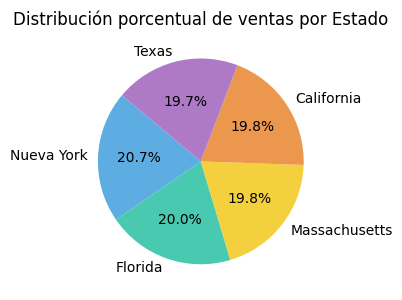

In [ ]:
# Importamos matplotlib para graficar
import matplotlib.pyplot as plt
import numpy as np

porcentajes_estados = df["Estado"].value_counts(normalize=True) * 100
plt.figure(figsize=(4, 4))
plt.pie(porcentajes_estados,labels=porcentajes_estados.index,autopct='%1.1f%%',startangle=140,colors=['#5dade2', '#48c9b0', '#f4d03f', '#eb984e', '#af7ac5'])
plt.title('Distribución porcentual de ventas por Estado')
plt.tight_layout()
plt.show()

A partir del equilibrio del gráfico notamos que la proporción de ventas por Estado esta prácticamente igualada, habiendo apenas un 1% del share de diferencia entre Nueva York y Texas, los Estados con mayor y menor cantidad de ventas, respectivamente.

In [ ]:
# Hacemos lo mismo con las ciudades

df["Ciudad"].value_counts()

,count
Ciudad,
Austin,535
Yonkers,529
Jacksonville,522
Buffalo,521
New York City,512
Tampa,508
San Francisco,508
Rochester,507
Boston,507


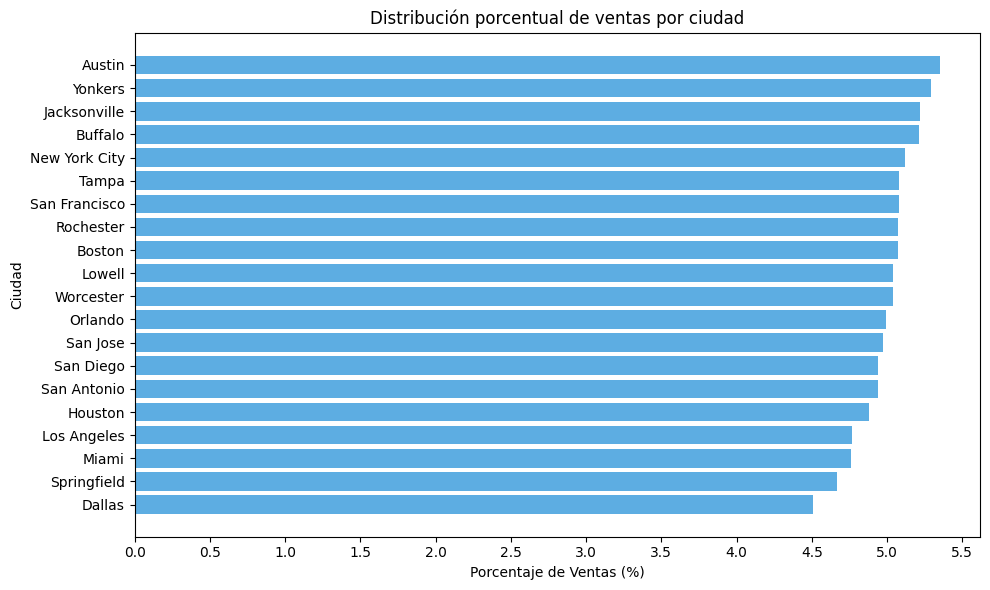

In [ ]:
#Nuevamente transladamos a porcentajes para graficar

ventas_ciudades = df["Ciudad"].value_counts(normalize=True) * 100

plt.figure(figsize=(10, 6))
plt.barh(ventas_ciudades.index, ventas_ciudades.values, color='#5dade2')
plt.xticks(np.arange(0, 6.0, 0.5))
plt.title('Distribución porcentual de ventas por ciudad')
plt.xlabel('Porcentaje de Ventas (%)')
plt.ylabel('Ciudad')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Mediante este gráfico de barras vemos que entre ciudades hay una tendencia muy similar a los Estados, habiendo poca diferencia relativa (menor al 1%) entre las ciudades con mayor y menor cantidad de ventas.

De esta forma, podemos concluir que la geografía no es un factor diferencial a la hora de contabilizar las ventas, teniendo todos los agentes presentes números bastante simiares entre sí.

### 3.2 Por mes

In [ ]:
# Creamos una tabla que nos muestre la cantidad de ventas en cada mes
ventas_por_mes = df.groupby(df['Fecha'].dt.to_period('M')).agg(Cantidad_de_ventas=('ID Orden', 'count')).reset_index()

ventas_por_mes.columns = ['Mes', 'Cantidad de ventas']

ventas_por_mes

,Mes,Cantidad de ventas
0,2024-01,851
1,2024-02,805
2,2024-03,836
3,2024-04,814
4,2024-05,873
5,2024-06,845
6,2024-07,825
7,2024-08,859
8,2024-09,824
9,2024-10,865


Con esta tabla podemos ver que no hay una relación lineal entre cantidad de ventas y unidades totales vendidas, ya que las órdenes pueden tener cualquier cantidad de productos.

### 3.3 Por vendedores y supermercados

In [ ]:
df["Vendedor"].value_counts()

,count
Vendedor,
Lee Charlotte,1541
Smith Noah,1463
Anderson James,1446
Davis Olivia,1438
Zeller Sophie,1422
Williams Chloe,1367
Jackson George,1323


En esta nueva categoría de diferenciación, se mantiene la tendencia de estadísticas bastante similares en cuestión de cantidad.

In [ ]:
df["Supermercado"].value_counts()

,count
Supermercado,
Exquisite Foods Market,549
The Family Grocer,540
My Market,530
Select Market,519
Super Saber,516
Sky Blue Market,511
Hyper Foods,504
The Food Barn,504
The Grocery Store,503


In [ ]:
df["Representante"].value_counts()

,count
Representante,
Rogers Harper,549
Brown Margaret,540
Johnson Alice,530
Bélanger Theodore,519
Lee Lucas,516
Taylor Jacob,511
Brightman Abigail,504
Tremblay Ana,504
McBride Evelyn,503


Comparando estas últimas dos tablas, vemos que las columnas 'Supermercado' y 'Representante' son redundantes, ya que expresan las mismas cantidades.

### 3.4 Por categoría y producto

In [ ]:
# Calculamos en cuántas categorías se distribuyen los productosy cuántas transacciones hubo para cada una de ellas

df["Categoría"].value_counts()

,count
Categoría,
Mantequilla,1712
Leche,1691
Otros,1677
Quesos,1659
Yogur,1640
Cremas,1621


In [ ]:
# Acá desglosamos cada una de ellas en todos los distintos productos que las componen y sus respectivas ventas

df["Producto"].value_counts()

,count
Producto,
Mantequilla con sal,591
Mantequilla sin sal,581
Mantequilla clarificada (ghee),540
Suero de leche,446
Dulce de leche,435
Yogur griego,434
Queso crema,427
Yogur con frutas,417
Cuajada,404


Analizando esta tabla, podemos notar una clara diferenciación entre los tipos de productos y su ubicación en la tabla. Aquellos que pertenecen a categorías que están compuestas por mayor cantidad de productos distintos, como los quesos y las leches, quedan desplazados al fondo de la lista. En contraposición, la cima está ocupada por aquellos de categorías con menor distribución, como las mantequillas y los yogures.

## 4. Resultados económicos

En esta sección buscaremos analizar la facturación según los distintos criterios

### 4.1 Por mes

In [ ]:
# Creamos una tabla que indique cuánto se facturó en cada mes

valor_ventas_por_mes=df.groupby(df['Fecha'].dt.to_period('M'))['Valor total (USD)'].sum().reset_index()
valor_ventas_por_mes.columns = ['Mes', 'Valor de ventas']

valor_ventas_por_mes

,Mes,Valor de ventas
0,2024-01,1359191.44
1,2024-02,1362556.56
2,2024-03,1388196.67
3,2024-04,1316584.49
4,2024-05,1385403.27
5,2024-06,1447826.42
6,2024-07,1325742.04
7,2024-08,1416870.09
8,2024-09,1296624.50
9,2024-10,1391692.14


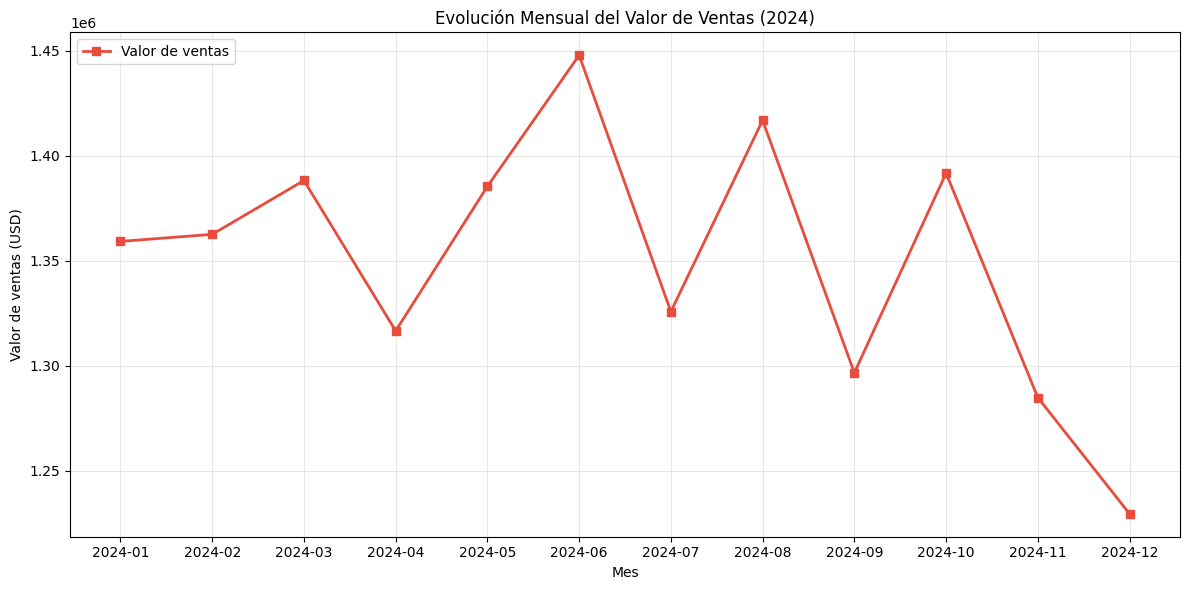

In [ ]:

meses_str = resumen_mensual['Mes'].astype(str)
plt.figure(figsize=(12, 6))
color = '#e74c3c'
plt.plot(meses_str, resumen_mensual['Valor de ventas'], color=color, marker='s', linewidth=2, label='Valor de ventas')
plt.xlabel('Mes')
plt.ylabel('Valor de ventas (USD)')
plt.title('Evolución Mensual del Valor de Ventas (2024)')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.tight_layout()

plt.show()

A partir del gráfico, es fácil notar que la facturación de las ventas es totalmente cambiante mes a mes, con constantes cambios de pendientes y nunca alcanzando más de dos meses consecutivos en alza o en baja.

### 4.2 Por Estado y ciudad

In [ ]:
# Creamos una tabla que muestre la facturación por Estado

ventas_por_estado = df.groupby(['Estado']).agg(
    Total_Ventas_USD=('Valor total (USD)', 'sum'),
).reset_index()

In [ ]:
ventas_por_estado.columns=['Estado','Total de ventas (USD)']

In [ ]:
ventas_por_estado

,Estado,Total_Ventas_USD
0,California,3170888.83
1,Florida,3349808.18
2,Massachusetts,3187427.25
3,Nueva York,3351058.76
4,Texas,3145841.90


Nueva York es el Estado que más facturó a lo largo del año y Texas el que menos, con una diferencia de $205216.86

In [ ]:
# Ahora con las ciudades
df.groupby(['Ciudad']).agg(
    Total_Ventas_USD=('Valor total (USD)', 'sum'),
).reset_index()


,Ciudad,Total_Ventas_USD
0,Austin,874974.94
1,Boston,828925.40
2,Buffalo,848362.36
3,Dallas,701122.00
4,Houston,775024.48
5,Jacksonville,887966.91
6,Los Angeles,743912.64
7,Lowell,829920.63
8,Miami,813727.61
9,New York City,841410.72


Jacksonville es la ciudad que más facturó, con $186844.91 más que Dallas, la que menos.

### 4.3 Por categoría

In [ ]:
df.groupby(['Categoría']).agg(
    Total_Ventas_USD=('Valor total (USD)', 'sum'),
).reset_index()

,Categoría,Total_Ventas_USD
0,Cremas,3020808.47
1,Leche,1579016.10
2,Mantequilla,3985112.60
3,Otros,2119674.20
4,Quesos,4006620.95
5,Yogur,1493792.60


In [ ]:
# Transformamos a porcentajes
ventas_categoria = df.groupby(['Categoría']).agg(
    Total_Ventas_USD=('Valor total (USD)', 'sum')
).reset_index()
total_general = ventas_categoria['Total_Ventas_USD'].sum()
ventas_categoria['Porcentaje (%)'] = (ventas_categoria['Total_Ventas_USD'] / total_general) * 100

ventas_categoria[['Categoría', 'Porcentaje (%)']]

,Categoría,Porcentaje (%)
0,Cremas,18.641184
1,Leche,9.743991
2,Mantequilla,24.591833
3,Otros,13.080351
4,Quesos,24.724559
5,Yogur,9.218083


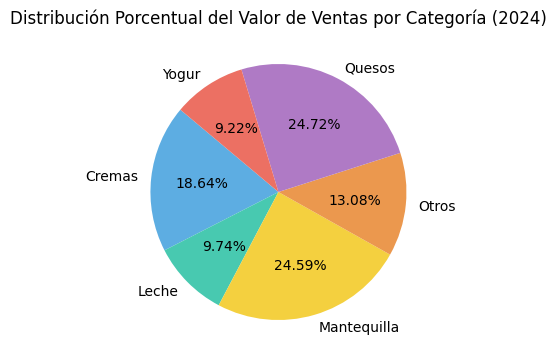

In [ ]:
# Generamos el gráfico de torta para las categorías y sus porcentajes
plt.figure(figsize=(4, 4))
plt.pie(
    ventas_categoria['Porcentaje (%)'],
    labels=ventas_categoria['Categoría'],
    autopct='%1.2f%%',
    startangle=140,
    colors=['#5dade2', '#48c9b0', '#f4d03f', '#eb984e', '#af7ac5', '#ec7063']
)
plt.title('Distribución Porcentual del Valor de Ventas por Categoría (2024)')
plt.tight_layout()
plt.show()

Comparando lo factuado por cada categoría, vemos que los quesos y las mantequillas tienen una amplia diferencia por sobre las otras, acaparando casi el 50% del share, dejando muy atrás a las leches y los yogures que juntan menos de 10% cada una.

### 4.4 Por producto

In [ ]:
df.groupby(['Producto']).agg(
    Total_Ventas_USD=('Valor total (USD)', 'sum'),
).reset_index()

,Producto,Total_Ventas_USD
0,Bebidas lácteas,154049.20
1,Crema agria,489835.00
2,Crema batida,739616.25
3,Crema de leche,1209968.02
4,Cuajada,449253.20
5,Dulce de leche,635718.00
6,Helado,589907.00
7,Kumis,485252.50
8,Leche condensada,240802.50
9,Leche descremada,86818.45


A partir de esta tabla, podemos ver que hay productos que destacan por sobre los demás: las mantequillas (con sal, sin sal y sobre todo la clarificada) y la crema de leche superan el millón de dólares en facturación, mientras que el resto no alcanza los $740000.

## 5. Planteos y conclusiones

### 5.1 Pregunta 1: ¿Qué factores fueron los que generaron mejores resultados de facturación a lo largo del año?

En primera instancia uno podría suponer que a más ventas mayores ganancias, sin embargo si comparamos las tablas generadas previamente, veremos que no fue exactamente así.

In [ ]:
# Combinamos las tablas de ventas y facturación

resumen_mensual = pd.merge(ventas_por_mes, valor_ventas_por_mes, on='Mes')
resumen_mensual

,Mes,Cantidad de ventas,Valor de ventas
0,2024-01,851,1359191.44
1,2024-02,805,1362556.56
2,2024-03,836,1388196.67
3,2024-04,814,1316584.49
4,2024-05,873,1385403.27
5,2024-06,845,1447826.42
6,2024-07,825,1325742.04
7,2024-08,859,1416870.09
8,2024-09,824,1296624.50
9,2024-10,865,1391692.14


Vemos así que los meses con mayores ventas no fueron los que más ganancias generaron, por lo que el dato clave para la facturación no está en la cantidad sino en la calidad. Hemos visto previamente que las categorías 'quesos' y 'mantequillas' eran las grandes estrellas de la recaudación, y que había cuatro productos (mantequillas clarificadas, con sal, sin sal y crema de leche) con los que ocurría lo mismo. Vamos entonces a ver cómo influyen esas variables en algunos puntos clave.

#### 5.1.1 Comparación entre meses

In [ ]:
# Agarraremos el mes de mayor facturación y veremos los resultados por producto

mes_seleccionado = 6  # Junio

ventas_por_mes_junio = (
    df[df['Fecha'].dt.month == mes_seleccionado]
    .groupby('Producto')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
    .sort_values(by='Valor_total_USD', ascending=False)
)

ventas_por_mes_junio

,Producto,Valor_total_USD,Unidades_vendidas
16,Mantequilla clarificada (ghee),136740.75,23781
18,Mantequilla sin sal,114550.80,27274
3,Crema de leche,108436.97,18103
17,Mantequilla con sal,104048.00,26012
2,Crema batida,65688.75,17517
6,Helado,57582.50,19626
5,Dulce de leche,48543.00,16181
30,Queso havarti,48347.25,9209
7,Kumis,44250.00,17700
25,Queso crema,43965.60,15702


In [ ]:
# Hacemos lo propio pero con las categorías y calculamos su porcentaje de ventas

ventas_por_categoria_junio = (
    df[df['Fecha'].dt.month == mes_seleccionado]
    .groupby('Categoría')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
    .sort_values(by='Valor_total_USD', ascending=False)
)

# Calculamos la columna de porcentaje sobre el total de ventas (USD)
total_ventas_junio = ventas_por_categoria_junio['Valor_total_USD'].sum()
ventas_por_categoria_junio['Porcentaje_Ventas (%)'] = (ventas_por_categoria_junio['Valor_total_USD'] / total_ventas_junio) * 100

ventas_por_categoria_junio

,Categoría,Valor_total_USD,Unidades_vendidas,Porcentaje_Ventas (%)
4,Quesos,408955.80,83442,28.246190
2,Mantequilla,355339.55,77067,24.542966
0,Cremas,250356.32,64228,17.291874
3,Otros,180534.10,71234,12.469319
5,Yogur,129909.80,69749,8.972747
1,Leche,122730.85,65245,8.476904


Aquí vemos que por un lado, de los cuatro productos destacados, tres estuvieron en el podio de más vendidos y los cuatro fueron los que más facturaron durante junio, el mes de mayor recaudación. A su vez, la categoría quesos fue la que mayor porcentaje del total recaudó, superando por bastante su promedio de 24,72% anual.

In [ ]:
# Haremos el mismo procedimiento con diciembre, el mes de menor facturación

mes_seleccionado = 12  # Diciembre

ventas_por_categoria_diciembre = (
    df[df['Fecha'].dt.month == mes_seleccionado]
    .groupby('Producto')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
    .sort_values(by='Valor_total_USD', ascending=False)
)

ventas_por_categoria_diciembre

,Producto,Valor_total_USD,Unidades_vendidas
18,Mantequilla sin sal,118582.80,28234
16,Mantequilla clarificada (ghee),116518.00,20264
3,Crema de leche,108598.70,18130
17,Mantequilla con sal,66224.00,16556
2,Crema batida,64391.25,17171
5,Dulce de leche,59352.00,19784
35,Suero de leche,51424.00,25712
6,Helado,46462.00,15956
7,Kumis,46307.50,18523
1,Crema agria,41040.00,16416


In [ ]:
# Ahora con las categorías

mes_seleccionado = 12  # Diciembre

ventas_por_categoria_diciembre = (
    df[df['Fecha'].dt.month == mes_seleccionado]
    .groupby('Categoría')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
    .sort_values(by='Valor_total_USD', ascending=False)
)

# Calculamos la columna de porcentaje sobre el total de ventas (USD) de diciembre
total_ventas_diciembre = ventas_por_categoria_diciembre['Valor_total_USD'].sum()
ventas_por_categoria_diciembre['Porcentaje_Ventas (%)'] = (ventas_por_categoria_diciembre['Valor_total_USD'] / total_ventas_diciembre) * 100

ventas_por_categoria_diciembre

,Categoría,Valor_total_USD,Unidades_vendidas,Porcentaje_Ventas (%)
2,Mantequilla,301324.80,65054,24.508032
4,Quesos,276362.25,58083,22.477722
0,Cremas,251894.35,65240,20.487643
3,Otros,189945.40,76319,15.449070
5,Yogur,112115.50,60593,9.118832
1,Leche,97851.75,58302,7.958701


Para este mes, vemos que si bien los mencionados cuatro productos fueron los de mayor recaudación, no se lucieron tanto en el total de ventas, por lo que se perdió un margen. A su vez, con respecto a las categorías, los quesos esta vez quedaron en segundo lugar tras las mantequillas, y no alcanzaron su promedio anual.

En conclusión, las principales claves de recaudación de mes a mes fueron dos: qué tan dominante fue la categoría 'quesos' ante las demás y qué tan dominantes fueron los productos de mantequilla, sobre todo la clarificada.
A continuación, veremos un gráfico de la evolución mensual de los quesos y las mantequillas, y así veremos como los picos de estas categorías coinciden con los meses de mayor facturación, y los puntos bajos coinciden con los de menor.

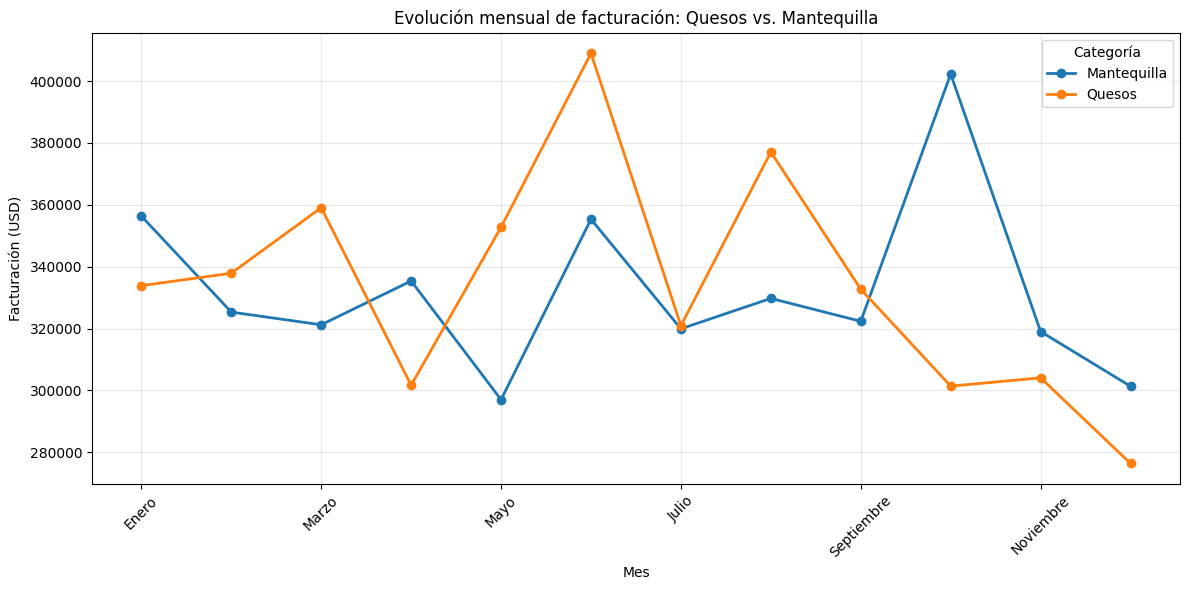

In [ ]:
# Graficamos la evolución mes a mes de estas dos categorías

categorias = ['Quesos', 'Mantequilla']

df_filtrado = df[df['Categoría'].isin(categorias)]

evolucion = (
    df_filtrado
    .groupby([df_filtrado['Fecha'].dt.month, 'Categoría'])
    ['Valor total (USD)']
    .sum()
    .unstack(fill_value=0)
)

evolucion = evolucion.reindex(range(1, 13), fill_value=0)

meses = [
    'Enero', 'Febrero', 'Marzo', 'Abril',
    'Mayo', 'Junio', 'Julio', 'Agosto',
    'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'
]

evolucion.index = meses

evolucion.plot(
    kind='line',
    marker='o',
    figsize=(12, 6),
    linewidth=2
)

plt.title('Evolución mensual de facturación: Quesos vs. Mantequilla')
plt.xlabel('Mes')
plt.ylabel('Facturación (USD)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(title='Categoría')
plt.tight_layout()
plt.show()

### 5.2 Pregunta 2: ¿Qué diferencias hay entre los comportamientos de las ciudades?

¿Seguirán todas las ciudades un patrón similar, o habrá alguna que se distinga? Para resolver esto vamos a comparar los números

In [ ]:
# Unimos las dos tablas de ventas por ciudad
pd.merge(cantidad_ventas_ciudad, valores_ventas_ciudad, on='Ciudad')

,Ciudad,Cantidad_de_ventas,Unidades_vendidas,Total_Ventas_USD
0,Austin,535,273080,874974.94
1,Boston,507,257938,828925.40
2,Buffalo,521,253390,848362.36
3,Dallas,451,221603,701122.00
4,Houston,488,235935,775024.48
5,Jacksonville,522,268710,887966.91
6,Los Angeles,477,225885,743912.64
7,Lowell,504,250369,829920.63
8,Miami,476,240223,813727.61
9,New York City,512,260585,841410.72


Comparando entre cantidad de ventas y facturación, la mayoría de las ciudades mantienen su puesto en el ranking o sufren variaciones de uno o dos puestos. Sin embargo, hay dos ciudades que saltan la norma: Tampa y Miami

Por un lado, Tampa se muestra como la séptima ciudad con más ventas, mientras que baja al décimo puesto en facturación. Opuestamente, Miami, que figura en el puesto 18 en cantidad de ventas, escala al puesto 12 en ganancia.
Para entender qué ocurrió en estas ciudades que causó dicha variación, vamos a compararlos con ciudades que hayan tenido un volumen similar de ventas.

#### 5.2.1 Comparación entre ciudades

In [ ]:
# Seleccionamos a la ciudad de Tampa y vemos sus datos de ventas por producto

ciudad_seleccionada = 'Tampa'

ventas_por_producto_tampa = (
    df[df['Ciudad'] == ciudad_seleccionada]
    .groupby('Producto')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
)
ventas_por_producto_tampa


,Producto,Valor_total_USD,Unidades_vendidas
0,Bebidas lácteas,7914.00,4299
1,Crema agria,28147.50,11259
2,Crema batida,33048.75,8813
3,Crema de leche,88574.13,14787
4,Cuajada,27808.00,12640
5,Dulce de leche,46926.00,15642
6,Helado,26422.25,10067
7,Kumis,27822.50,11129
8,Leche condensada,10470.00,4188
9,Leche descremada,3946.80,4752


In [ ]:
ciudad_seleccionada = 'Tampa'

ventas_por_categoría_tampa = (
    df[df['Ciudad'] == ciudad_seleccionada]
    .groupby('Categoría')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
)

# Calculamos el porcentaje que representa cada categoría sobre el total de ventas de Tampa
total_ventas_tampa = ventas_por_categoría_tampa['Valor_total_USD'].sum()
ventas_por_categoría_tampa['Porcentaje_Ventas (%)'] = (ventas_por_categoría_tampa['Valor_total_USD'] / total_ventas_tampa) * 100

ventas_por_categoría_tampa

,Categoría,Valor_total_USD,Unidades_vendidas,Porcentaje_Ventas (%)
0,Cremas,174849.98,43816,21.324979
1,Leche,74439.25,40868,9.078728
2,Mantequilla,186005.75,40303,22.685554
3,Otros,123394.25,49468,15.049357
4,Quesos,190923.55,39445,23.285337
5,Yogur,70317.60,40811,8.576045


In [ ]:
# Tomamos como punto de comparación la ciudad de Buffalo

ciudad_seleccionada = 'Buffalo'

ventas_por_producto_buffalo = (
    df[df['Ciudad'] == ciudad_seleccionada]
    .groupby('Producto')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
)
ventas_por_producto_buffalo

,Producto,Valor_total_USD,Unidades_vendidas
0,Bebidas lácteas,12850.80,7641
1,Crema agria,25995.00,10398
2,Crema batida,35261.25,9403
3,Crema de leche,47794.21,7979
4,Cuajada,24461.80,11119
5,Dulce de leche,22257.00,7419
6,Helado,33080.75,11162
7,Kumis,23607.50,9443
8,Leche condensada,10795.00,4318
9,Leche descremada,4652.65,4741


In [ ]:
ciudad_seleccionada = 'Buffalo'

ventas_por_categoría_buffalo = (
    df[df['Ciudad'] == ciudad_seleccionada]
    .groupby('Categoría')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
)

total_ventas_buffalo = ventas_por_categoría_buffalo['Valor_total_USD'].sum()
ventas_por_categoría_buffalo['Porcentaje_Ventas (%)'] = (ventas_por_categoría_buffalo['Valor_total_USD'] / total_ventas_buffalo) * 100

ventas_por_categoría_buffalo

,Categoría,Valor_total_USD,Unidades_vendidas,Porcentaje_Ventas (%)
0,Cremas,146237.26,41061,17.237594
1,Leche,76300.30,42437,8.993834
2,Mantequilla,223810.25,47839,26.381445
3,Otros,104439.55,42020,12.310724
4,Quesos,232807.60,47325,27.442000
5,Yogur,64767.40,32708,7.634403


A partir de la comparación entre Tampa y Buffalo, podemos notar que el grueso de la recaudación estuvo nuevamente en los quesos y las mantequillas. Mientras que en Buffalo estos productos brillaron, en Tampa tuvieron números muy por debajo de su promedio.

Procedemos a comparar Miami con Houston para ver si vuelve a cumplirse la tendencia.

In [ ]:
# Ahora compararemos a la ciudad de Miami

ciudad_seleccionada = 'Miami'

ventas_por_producto_miami = (
    df[df['Ciudad'] == ciudad_seleccionada]
    .groupby('Producto')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
)

ventas_por_producto_miami

,Producto,Valor_total_USD,Unidades_vendidas
0,Bebidas lácteas,6302.80,4161
1,Crema agria,13772.50,5509
2,Crema batida,32887.50,8770
3,Crema de leche,59624.46,9954
4,Cuajada,22151.80,10069
5,Dulce de leche,23082.00,7694
6,Helado,47567.25,13028
7,Kumis,23347.50,9339
8,Leche condensada,15307.50,6123
9,Leche descremada,3962.70,4128


In [ ]:
ciudad_seleccionada = 'Miami'

ventas_por_categoría_miami = (
    df[df['Ciudad'] == ciudad_seleccionada]
    .groupby('Categoría')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
)

total_ventas_miami = ventas_por_categoría_miami['Valor_total_USD'].sum()
ventas_por_categoría_miami['Porcentaje_Ventas (%)'] = (ventas_por_categoría_miami['Valor_total_USD'] / total_ventas_miami) * 100

ventas_por_categoría_miami

,Categoría,Valor_total_USD,Unidades_vendidas,Porcentaje_Ventas (%)
0,Cremas,127368.46,31763,15.652469
1,Leche,77208.35,40594,9.488230
2,Mantequilla,183805.55,39621,22.588093
3,Otros,113751.05,41266,13.979008
4,Quesos,239262.60,49221,29.403279
5,Yogur,72331.60,37758,8.888920


In [ ]:
# El punto de comparación será Los Angeles

ciudad_seleccionada = 'Los Angeles'

ventas_por_producto_LA = (
    df[df['Ciudad'] == ciudad_seleccionada]
    .groupby('Producto')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
)

ventas_por_producto_LA

,Producto,Valor_total_USD,Unidades_vendidas
0,Bebidas lácteas,6694.00,4429
1,Crema agria,11477.50,4591
2,Crema batida,32700.00,8720
3,Crema de leche,80361.84,13416
4,Cuajada,22178.20,10081
5,Dulce de leche,31512.00,10504
6,Helado,23156.25,10537
7,Kumis,25197.50,10079
8,Leche condensada,22547.50,9019
9,Leche descremada,1522.65,1851


In [ ]:
ciudad_seleccionada = 'Los Angeles'

ventas_por_categoría_LA = (
    df[df['Ciudad'] == ciudad_seleccionada]
    .groupby('Categoría')
    .agg(
        Valor_total_USD=('Valor total (USD)', 'sum'),
        Unidades_vendidas=('Cantidad comprada', 'sum')
    )
    .reset_index()
)

total_ventas_LA = ventas_por_categoría_LA['Valor_total_USD'].sum()
ventas_por_categoría_LA['Porcentaje_Ventas (%)'] = (ventas_por_categoría_LA['Valor_total_USD'] / total_ventas_LA) * 100

ventas_por_categoría_LA

,Categoría,Valor_total_USD,Unidades_vendidas,Porcentaje_Ventas (%)
0,Cremas,138707.34,31787,18.645649
1,Leche,82562.45,39181,11.098407
2,Mantequilla,154979.70,33381,20.833051
3,Otros,93448.45,39423,12.561751
4,Quesos,200150.50,42368,26.905108
5,Yogur,74064.20,39745,9.956035


Al comparar estas otras dos ciudades, comprobamos lo esperado: en Miami, donde la facturación fue mayor a lo esperado, los quesos y las mantequillas tuvieron números por encima del promedio, mientras que en Los Angeles los resultados de las categorías mencionadas fueron bastante similares a lo esperado.

### 5.3 Pregunta 3: ¿La fortaleza de los supermercados varía por Estado, o hay monopolio?

Nuestra último foco de análisis es qué tan repartido geográficamente está el poder de los mercados. Para resolverlo vamos a comparar cuánto vende cada uno y dónde.

In [ ]:
# 1. Cruzamos los datos de cantidad de ventas por supermercado y Estado
ventas_super_estado = df.pivot_table(
    index='Supermercado',
    columns='Estado',
    values='ID Orden',
    aggfunc='count',
    fill_value=0
)

print("--- Matriz de cantidad de ventas por Supermercado y Estado ---")
display(ventas_super_estado)


--- Matriz de cantidad de ventas por Supermercado y Estado ---


Estado,California,Florida,Massachusetts,Nueva York,Texas
Supermercado,,,,,
Central Supermarket,90,90,91,110,94
Corner Delicatessen,98,111,93,110,89
Culinary Treasures,87,87,107,106,109
Exquisite Foods Market,105,110,118,103,113
Food Emporium,89,87,88,102,95
Hyper Foods,98,98,108,105,95
My Market,100,111,94,132,93
Pekos Foods,112,99,97,101,94
Red Rose,107,87,83,105,95


A partir de esta tabla podemos notar que en cada Estado un supermercado distinto lidera en ventas, por lo que concluimos que no hay una red ampliamente dominante, sino que todos tienen presencias similares pero con focos principales en distintos lugares.

## 6. Exportación a PowerBI

In [ ]:
# Guardamos el DataFrame procesado en un archivo CSV listo para Power BI
df.to_csv('ventas_lacteos_analizado.csv', index=False)